# Spectrogram Autoencoder


## Imports & Config

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import copy
import joblib
import pywt
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.signal import stft
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

work_dir = os.getcwd()
print("work_dir:", work_dir)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device  :", DEVICE)

# Paths
DATA_DIR = os.path.join(work_dir, "data_cnn_normalized")
SPEC_DIR = os.path.join(work_dir, "data_spectrograms_v2")
MODEL_DIR = os.path.join(work_dir, "model")
FIG_DIR = os.path.join(work_dir, "figures", "SpectroAE_v2")
for d in [SPEC_DIR, MODEL_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

# STFT config
FS = 1 / 1800
NPERSEG = 64
NOVERLAP = 48

# CWT config
CWT_WAVELET = "morl"
CWT_SCALES = np.geomspace(2, 256, num=32)
CWT_DECIMATE = 8


# Model / training config
AE_CONFIG = {
    "latent_dim": 128,
    "batch_size": 64,
    "dropout": 0.2,
    "weight_decay": 1e-5,
    "huber_delta": 2.0,
    "lr_pretrain": 1e-3,
    "pretrain_epochs": 100,
    "pretrain_patience": 20,
    "lr_p2_warmup": 5e-3,
    "lr_p2_main": 1e-4,
    "warmup_steps": 200,
    "finetune_epochs": 150,
    "finetune_patience": 20,
    "lr_e2e": 5e-5,
    "e2e_epochs": 60,
    "e2e_patience": 10,
    "e2e_plat_patience": 3,
    "e2e_plat_factor": 0.3,
}

print("\nSTFT output shape (W=1166):")
dummy = np.zeros(1166)
_, _, Zxx = stft(dummy, fs=FS, nperseg=NPERSEG, noverlap=NOVERLAP)
print(f"  freq bins  : {Zxx.shape[0]}")
print(f"  time frames: {Zxx.shape[1]}")

print(f"\nCWT output shape (W=1166, decimate={CWT_DECIMATE}):")
print(f"  scales     : {len(CWT_SCALES)}")
print(f"  time frames: {1166 // CWT_DECIMATE}")

work_dir: /content
device  : cuda

STFT output shape (W=1166):
  freq bins  : 33
  time frames: 74

CWT output shape (W=1166, decimate=8):
  scales     : 32
  time frames: 145



# STEP 1 — Load Normalized Windows

In [2]:
X_train = np.load(os.path.join(DATA_DIR, "X_train.npy"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
X_val = np.load(os.path.join(DATA_DIR, "X_val.npy"))
y_val = np.load(os.path.join(DATA_DIR, "y_val.npy"))
X_test = np.load(os.path.join(DATA_DIR, "X_test.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))

N_CH = X_train.shape[2]
W = X_train.shape[1]

print(f"Train : {X_train.shape}  y=[{y_train.min():.2f}, {y_train.max():.2f}]")
print(f"Val   : {X_val.shape}    y=[{y_val.min():.2f}, {y_val.max():.2f}]")
print(f"Test  : {X_test.shape}   y=[{y_test.min():.2f}, {y_test.max():.2f}]")

Train : (9161, 1166, 5)  y=[70.00, 97.65]
Val   : (1776, 1166, 5)    y=[70.01, 97.92]
Test  : (1743, 1166, 5)   y=[70.04, 95.38]



# STEP 2 — Pre-compute Spectrograms (STFT + CWT)

In [3]:
def compute_stft(X, desc=""):
    N, T, C = X.shape
    specs = []
    for i in range(N):
        ch_specs = []
        for ch in range(C):
            _, _, Zxx = stft(X[i, :, ch], fs=FS, nperseg=NPERSEG, noverlap=NOVERLAP)
            ch_specs.append(np.log1p(np.abs(Zxx)).astype(np.float32))
        specs.append(np.stack(ch_specs, axis=0))
        if (i + 1) % 1000 == 0 or i == N - 1:
            print(f"  STFT {desc}: {i + 1}/{N}", end="\r")
    print()
    return np.stack(specs, axis=0)


def compute_cwt(X, desc=""):
    N, T, C = X.shape
    D = CWT_DECIMATE
    specs = []
    for i in range(N):
        ch_specs = []
        for ch in range(C):
            sig = X[i, ::D, ch]  # decimate
            coeffs, _ = pywt.cwt(sig, CWT_SCALES, CWT_WAVELET)
            log_pow = np.log1p(np.abs(coeffs) ** 2).astype(np.float32)
            ch_specs.append(log_pow)  # (scales, T//D)
        specs.append(np.stack(ch_specs, axis=0))
        if (i + 1) % 500 == 0 or i == N - 1:
            print(f"  CWT  {desc}: {i + 1}/{N}", end="\r")
    print()
    return np.stack(specs, axis=0)


def cache(X, name, fn, desc):
    path = os.path.join(SPEC_DIR, f"{name}.npy")
    if os.path.exists(path):
        print(f"  Loading cached: {name}.npy")
        return np.load(path)
    print(f"  Computing: {name}...")
    arr = fn(X, desc=desc)
    np.save(path, arr)
    print(f"  Saved → {name}.npy  shape={arr.shape}")
    return arr


print("STFT")
S_stft_train = cache(X_train, "stft_train", compute_stft, "Train")
S_stft_val = cache(X_val, "stft_val", compute_stft, "Val")
S_stft_test = cache(X_test, "stft_test", compute_stft, "Test")

print("\n CWT")
S_cwt_train = cache(X_train, "cwt_train", compute_cwt, "Train")
S_cwt_val = cache(X_val, "cwt_val", compute_cwt, "Val")
S_cwt_test = cache(X_test, "cwt_test", compute_cwt, "Test")

STFT_SHAPE = S_stft_train.shape[1:]  # (C, F_stft, T_stft)
CWT_SHAPE = S_cwt_train.shape[1:]  # (C, scales, T_cwt)

print(f"\nSTFT shape per window: {STFT_SHAPE}")
print(f"CWT  shape per window: {CWT_SHAPE}")

── STFT ─────────────────────────
  Computing: stft_train...
  STFT Train: 9161/9161
  Saved → stft_train.npy  shape=(9161, 5, 33, 74)
  Computing: stft_val...
  STFT Val: 1776/1776
  Saved → stft_val.npy  shape=(1776, 5, 33, 74)
  Computing: stft_test...
  STFT Test: 1743/1743
  Saved → stft_test.npy  shape=(1743, 5, 33, 74)

── CWT ──────────────────────────
  Computing: cwt_train...
  CWT  Train: 9161/9161
  Saved → cwt_train.npy  shape=(9161, 5, 32, 146)
  Computing: cwt_val...
  CWT  Val: 1776/1776
  Saved → cwt_val.npy  shape=(1776, 5, 32, 146)
  Computing: cwt_test...
  CWT  Test: 1743/1743
  Saved → cwt_test.npy  shape=(1743, 5, 32, 146)

STFT shape per window: (5, 33, 74)
CWT  shape per window: (5, 32, 146)


## Spectrogram Sanity Check

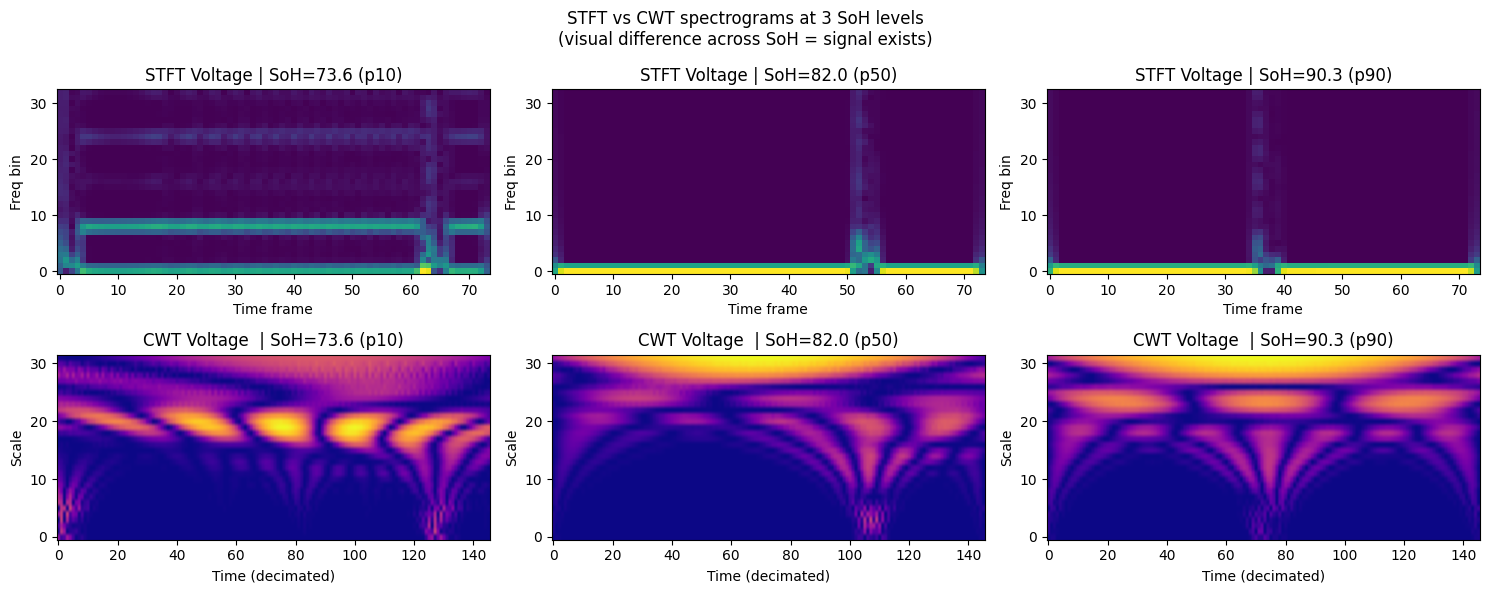

In [4]:
pcts = [10, 50, 90]
thresholds = np.percentile(y_train, pcts)
chosen = [np.argmin(np.abs(y_train - t)) for t in thresholds]
ch_names = ["Voltage", "Current", "Temperature", "dV/dt", "dI/dt"][:N_CH]

# Show voltage channel only for brevity
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col, (idx, pct) in enumerate(zip(chosen, pcts)):
    # STFT
    axes[0][col].imshow(
        S_stft_train[idx, 0], aspect="auto", origin="lower", cmap="viridis"
    )
    axes[0][col].set_title(f"STFT Voltage | SoH={y_train[idx]:.1f} (p{pct})")
    axes[0][col].set_ylabel("Freq bin")
    axes[0][col].set_xlabel("Time frame")
    # CWT
    axes[1][col].imshow(
        S_cwt_train[idx, 0], aspect="auto", origin="lower", cmap="plasma"
    )
    axes[1][col].set_title(f"CWT Voltage  | SoH={y_train[idx]:.1f} (p{pct})")
    axes[1][col].set_ylabel("Scale")
    axes[1][col].set_xlabel("Time (decimated)")

fig.suptitle(
    "STFT vs CWT spectrograms at 3 SoH levels\n"
    "(visual difference across SoH = signal exists)",
    fontsize=12,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig0_spectrograms.png"))
plt.show()


# STEP 3 — Model: Dual-Branch Encoder (STFT + CWT)



In [5]:
class CNN2DEncoder(nn.Module):
    """Shared 2D CNN encoder for one spectrogram type (STFT or CWT)."""

    def __init__(self, in_channels, out_dim, dropout):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 8)),  # fixed output regardless of input size
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 8, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, out_dim),
        )

    def forward(self, x):
        return self.fc(self.conv(x))


class CNN2DDecoder(nn.Module):
    """Decoder mirrors the encoder — reconstructs input spectrogram from z."""

    def __init__(self, out_channels, in_dim):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Linear(256, 128 * 4 * 8), nn.ReLU()
        )
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, out_channels, 3, padding=1),
        )

    def forward(self, z, target_hw):
        x = self.fc(z).view(-1, 128, 4, 8)
        x = self.deconv(x)
        return F.interpolate(x, size=target_hw, mode="bilinear", align_corners=False)


class SoHHead(nn.Module):
    def __init__(self, latent_dim, dropout):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, z):
        return self.mlp(z).squeeze(-1)


class DualBranchSpectroAE(nn.Module):
    def __init__(self, stft_shape, cwt_shape, latent_dim, dropout):
        super().__init__()
        half = latent_dim // 2
        C = stft_shape[0]

        self.stft_enc = CNN2DEncoder(C, half, dropout)
        self.cwt_enc = CNN2DEncoder(C, half, dropout)

        # One decoder per branch (they have different spatial dims)
        self.stft_dec = CNN2DDecoder(C, half)
        self.cwt_dec = CNN2DDecoder(C, half)

        self.soh_head = SoHHead(latent_dim, dropout)

    def encode(self, stft, cwt):
        z_s = self.stft_enc(stft)
        z_c = self.cwt_enc(cwt)
        return torch.cat([z_s, z_c], dim=1), z_s, z_c

    def forward(self, stft, cwt, mode="reconstruct"):
        z, z_s, z_c = self.encode(stft, cwt)

        if mode == "reconstruct":
            r_s = self.stft_dec(z_s, (stft.shape[2], stft.shape[3]))
            r_c = self.cwt_dec(z_c, (cwt.shape[2], cwt.shape[3]))
            return r_s, r_c

        elif mode == "predict":
            return self.soh_head(z)

        elif mode == "both":
            r_s = self.stft_dec(z_s, (stft.shape[2], stft.shape[3]))
            r_c = self.cwt_dec(z_c, (cwt.shape[2], cwt.shape[3]))
            return r_s, r_c, self.soh_head(z), z

    def get_latent(self, stft, cwt):
        with torch.no_grad():
            z, _, _ = self.encode(stft, cwt)
        return z


model = DualBranchSpectroAE(
    stft_shape=STFT_SHAPE,
    cwt_shape=CWT_SHAPE,
    latent_dim=AE_CONFIG["latent_dim"],
    dropout=AE_CONFIG["dropout"],
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

# Shape test
ds = torch.zeros(2, *STFT_SHAPE).to(DEVICE)
dc = torch.zeros(2, *CWT_SHAPE).to(DEVICE)
rs, rc = model(ds, dc, mode="reconstruct")
soh_out = model(ds, dc, mode="predict")
print(f"STFT input/recon : {ds.shape} → {rs.shape}")
print(f"CWT  input/recon : {dc.shape} → {rc.shape}")
print(f"SoH output       : {soh_out.shape}")

Trainable parameters: 4,921,483
STFT input/recon : torch.Size([2, 5, 33, 74]) → torch.Size([2, 5, 33, 74])
CWT  input/recon : torch.Size([2, 5, 32, 146]) → torch.Size([2, 5, 32, 146])
SoH output       : torch.Size([2])


## Dataset & Loaders

In [6]:
class DualSpectroDataset(Dataset):
    def __init__(self, S_stft, S_cwt, y):
        self.S_stft = torch.tensor(S_stft, dtype=torch.float32)
        self.S_cwt = torch.tensor(S_cwt, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.S_stft[idx], self.S_cwt[idx], self.y[idx]


BS = AE_CONFIG["batch_size"]

train_ds = DualSpectroDataset(S_stft_train, S_cwt_train, y_train)
val_ds = DualSpectroDataset(S_stft_val, S_cwt_val, y_val)
test_ds = DualSpectroDataset(S_stft_test, S_cwt_test, y_test)

train_loader = DataLoader(
    train_ds, batch_size=BS, shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=BS, shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_ds, batch_size=BS, shuffle=False, num_workers=0, pin_memory=True
)

print(f"Train batches: {len(train_loader)}")
print(f"Val   batches: {len(val_loader)}")
print(f"Test  batches: {len(test_loader)}")

Train batches: 144
Val   batches: 28
Test  batches: 28



# PHASE 1 — Unsupervised Reconstruction Pre-training


In [7]:
recon_criterion = nn.MSELoss()

# Only encoder + decoder params — SoH head excluded
ae_params = (
    list(model.stft_enc.parameters())
    + list(model.cwt_enc.parameters())
    + list(model.stft_dec.parameters())
    + list(model.cwt_dec.parameters())
)
optimizer_ae = torch.optim.Adam(
    ae_params, lr=AE_CONFIG["lr_pretrain"], weight_decay=AE_CONFIG["weight_decay"]
)
scheduler_ae = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ae, mode="min", factor=0.5, patience=8, min_lr=1e-6
)

p1_train, p1_val = [], []
best_ae_val = float("inf")
best_ae_state = None
counter = 0

print("PHASE 1 — Reconstruction pre-training")
print("=" * 60)

for epoch in range(1, AE_CONFIG["pretrain_epochs"] + 1):
    model.train()
    bl = []
    for Ss, Sc, _ in train_loader:
        Ss, Sc = Ss.to(DEVICE), Sc.to(DEVICE)
        rs, rc = model(Ss, Sc, mode="reconstruct")
        loss = recon_criterion(rs, Ss) + recon_criterion(rc, Sc)
        optimizer_ae.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(ae_params, 1.0)
        optimizer_ae.step()
        bl.append(loss.item())
    train_loss = np.mean(bl)

    model.eval()
    vl = []
    with torch.no_grad():
        for Ss, Sc, _ in val_loader:
            Ss, Sc = Ss.to(DEVICE), Sc.to(DEVICE)
            rs, rc = model(Ss, Sc, mode="reconstruct")
            vl.append((recon_criterion(rs, Ss) + recon_criterion(rc, Sc)).item())
    val_loss = np.mean(vl)

    p1_train.append(train_loss)
    p1_val.append(val_loss)
    scheduler_ae.step(val_loss)

    print(
        f"Ep {epoch:03d}/{AE_CONFIG['pretrain_epochs']} | "
        f"Train: {train_loss:.6f} | Val: {val_loss:.6f} | "
        f"LR: {optimizer_ae.param_groups[0]['lr']:.2e}"
    )

    if val_loss < best_ae_val:
        best_ae_val = val_loss
        best_ae_state = copy.deepcopy(model.state_dict())
        counter = 0
        torch.save(best_ae_state, os.path.join(MODEL_DIR, "spectro_ae_v2_p1.pt"))
        print(f"  ↳ New best ({best_ae_val:.6f})")
    else:
        counter += 1
    if counter >= AE_CONFIG["pretrain_patience"]:
        print("Early stopping")
        break

model.load_state_dict(best_ae_state)
print(f"\nPhase 1 complete. Best val recon: {best_ae_val:.6f}")

PHASE 1 — Reconstruction pre-training
Ep 001/100 | Train: 0.197970 | Val: 0.193235 | LR: 1.00e-03
  ↳ New best (0.193235)
Ep 002/100 | Train: 0.129933 | Val: 0.155851 | LR: 1.00e-03
  ↳ New best (0.155851)
Ep 003/100 | Train: 0.117156 | Val: 0.146619 | LR: 1.00e-03
  ↳ New best (0.146619)
Ep 004/100 | Train: 0.110143 | Val: 0.138460 | LR: 1.00e-03
  ↳ New best (0.138460)
Ep 005/100 | Train: 0.104568 | Val: 0.137998 | LR: 1.00e-03
  ↳ New best (0.137998)
Ep 006/100 | Train: 0.100671 | Val: 0.123530 | LR: 1.00e-03
  ↳ New best (0.123530)
Ep 007/100 | Train: 0.098994 | Val: 0.121487 | LR: 1.00e-03
  ↳ New best (0.121487)
Ep 008/100 | Train: 0.097130 | Val: 0.129003 | LR: 1.00e-03
Ep 009/100 | Train: 0.095840 | Val: 0.136816 | LR: 1.00e-03
Ep 010/100 | Train: 0.094674 | Val: 0.121403 | LR: 1.00e-03
  ↳ New best (0.121403)
Ep 011/100 | Train: 0.091872 | Val: 0.121346 | LR: 1.00e-03
  ↳ New best (0.121346)
Ep 012/100 | Train: 0.090670 | Val: 0.120047 | LR: 1.00e-03
  ↳ New best (0.120047)
Ep


# DIAGNOSTIC — Reconstruction Error vs SoH

Pearson r(SoH, recon_error) = -0.5079
✅  Strong signal — proceed to phase 2.


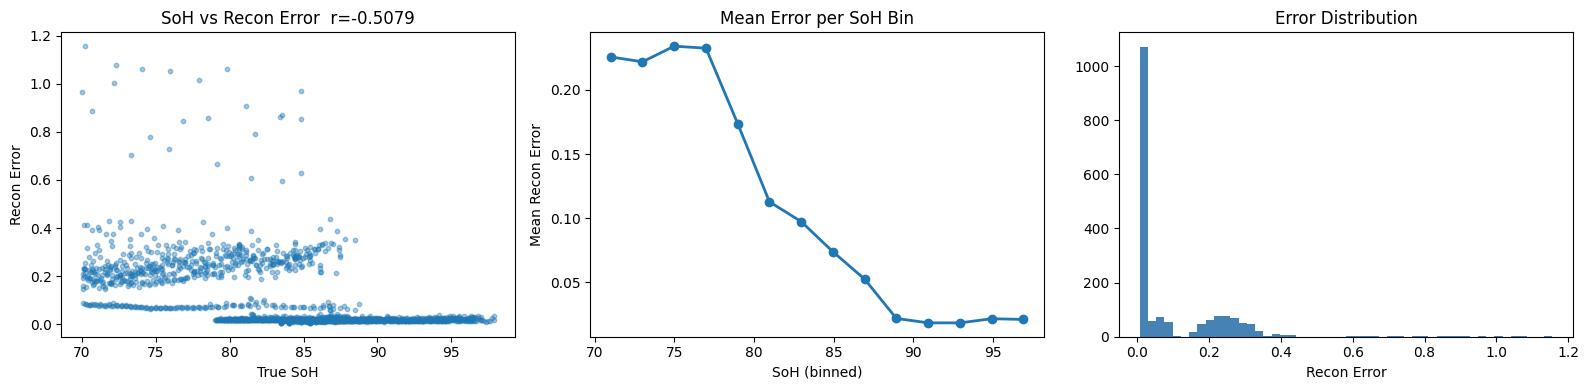

In [8]:
model.eval()
recon_errors, soh_vals = [], []

with torch.no_grad():
    for Ss, Sc, yb in val_loader:
        Ss, Sc = Ss.to(DEVICE), Sc.to(DEVICE)
        rs, rc = model(Ss, Sc, mode="reconstruct")
        # Combined per-sample reconstruction error
        err_s = ((rs - Ss) ** 2).mean(dim=(1, 2, 3)).cpu().numpy()
        err_c = ((rc - Sc) ** 2).mean(dim=(1, 2, 3)).cpu().numpy()
        recon_errors.extend((err_s + err_c).tolist())
        soh_vals.extend(yb.numpy().tolist())

recon_errors = np.array(recon_errors)
soh_vals = np.array(soh_vals)
r = np.corrcoef(soh_vals, recon_errors)[0, 1]

print(f"Pearson r(SoH, recon_error) = {r:.4f}")
if abs(r) > 0.3:
    print("✅  Strong signal — proceed to phase 2.")
elif abs(r) > 0.1:
    print("⚠️  Weak signal — phase 2 may still help.")
else:
    print("❌  No signal — consider per-battery normalization.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(soh_vals, recon_errors, alpha=0.4, s=10)
axes[0].set_xlabel("True SoH")
axes[0].set_ylabel("Recon Error")
axes[0].set_title(f"SoH vs Recon Error  r={r:.4f}")

bins = np.linspace(soh_vals.min(), soh_vals.max(), 15)
bin_idx = np.digitize(soh_vals, bins)
bin_means = [
    recon_errors[bin_idx == i].mean() if (bin_idx == i).sum() > 0 else np.nan
    for i in range(1, len(bins))
]
axes[1].plot((bins[:-1] + bins[1:]) / 2, bin_means, "o-", lw=2)
axes[1].set_xlabel("SoH (binned)")
axes[1].set_ylabel("Mean Recon Error")
axes[1].set_title("Mean Error per SoH Bin")

axes[2].hist(recon_errors, bins=50, color="steelblue", edgecolor="none")
axes[2].set_xlabel("Recon Error")
axes[2].set_title("Error Distribution")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig1_diagnostic.png"))
plt.show()

## Latent Space PCA

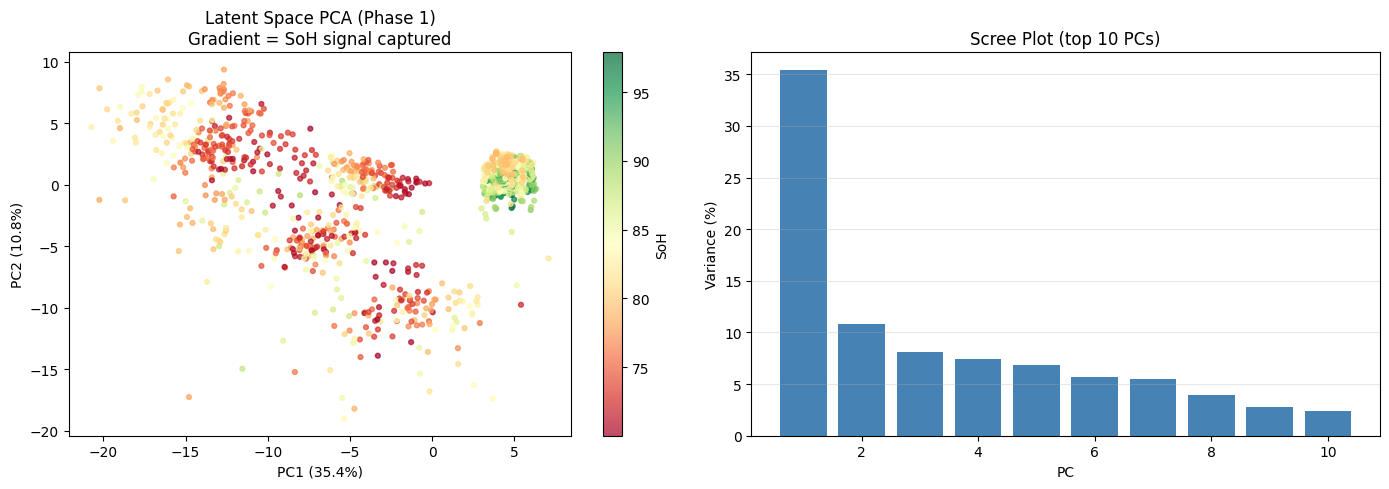

In [9]:
model.eval()
latents, sohs = [], []
with torch.no_grad():
    for Ss, Sc, yb in val_loader:
        z = model.get_latent(Ss.to(DEVICE), Sc.to(DEVICE)).cpu().numpy()
        latents.append(z)
        sohs.extend(yb.numpy().tolist())

Z = np.concatenate(latents)
y_soh = np.array(sohs)
Zc = Z - Z.mean(axis=0)
U, S, Vt = np.linalg.svd(Zc, full_matrices=False)
Z_pca = U[:, :2] * S[:2]
var = (S[:2] ** 2) / (S**2).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc = axes[0].scatter(Z_pca[:, 0], Z_pca[:, 1], c=y_soh, cmap="RdYlGn", s=12, alpha=0.7)
plt.colorbar(sc, ax=axes[0], label="SoH")
axes[0].set_xlabel(f"PC1 ({var[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({var[1]:.1%})")
axes[0].set_title("Latent Space PCA (Phase 1)\nGradient = SoH signal captured")

var10 = (S[:10] ** 2) / (S**2).sum() * 100
axes[1].bar(range(1, 11), var10, color="steelblue")
axes[1].set_xlabel("PC")
axes[1].set_ylabel("Variance (%)")
axes[1].set_title("Scree Plot (top 10 PCs)")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig2_latent_pca.png"))
plt.show()


# PHASE 2 — Frozen Encoder + SoH Head

In [10]:
# Freeze everything except SoH head
for name, param in model.named_parameters():
    param.requires_grad = "soh_head" in name

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Phase 2 trainable params: {trainable:,} (SoH head only)")

soh_criterion = nn.HuberLoss(delta=AE_CONFIG["huber_delta"])

# Start at high LR — warm-up avoids initial collapse
optimizer_ft = torch.optim.Adam(
    model.soh_head.parameters(),
    lr=AE_CONFIG["lr_p2_warmup"],
    weight_decay=AE_CONFIG["weight_decay"],
)
scheduler_ft = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft, mode="min", factor=0.5, patience=5, min_lr=1e-7
)

p2_train, p2_val_rmse = [], []
best_ft_val = float("inf")
best_ft_state = None
counter = 0
global_step = 0

print("\nPHASE 2 — SoH head fine-tuning")
print("=" * 60)

for epoch in range(1, AE_CONFIG["finetune_epochs"] + 1):
    model.train()
    bl = []
    for Ss, Sc, yb in train_loader:
        Ss, Sc, yb = Ss.to(DEVICE), Sc.to(DEVICE), yb.to(DEVICE)

        # Warm-up: drop LR after warmup_steps
        if global_step == AE_CONFIG["warmup_steps"]:
            for pg in optimizer_ft.param_groups:
                pg["lr"] = AE_CONFIG["lr_p2_main"]
            print(
                f"  ↳ LR dropped to {AE_CONFIG['lr_p2_main']:.1e} at step {global_step}"
            )

        pred = model(Ss, Sc, mode="predict")
        loss = soh_criterion(pred, yb)
        optimizer_ft.zero_grad()
        loss.backward()
        optimizer_ft.step()
        bl.append(loss.item())
        global_step += 1
    train_loss = np.mean(bl)

    model.eval()
    vp, vt, vl = [], [], []
    with torch.no_grad():
        for Ss, Sc, yb in val_loader:
            Ss, Sc, yb = Ss.to(DEVICE), Sc.to(DEVICE), yb.to(DEVICE)
            p = model(Ss, Sc, mode="predict")
            vl.append(soh_criterion(p, yb).item())
            vp.extend(p.cpu().numpy().tolist())
            vt.extend(yb.cpu().numpy().tolist())
    val_loss = np.mean(vl)
    val_rmse = np.sqrt(mean_squared_error(vt, vp))

    p2_train.append(train_loss)
    p2_val_rmse.append(val_rmse)
    # Only step scheduler after warm-up ends
    if global_step > AE_CONFIG["warmup_steps"]:
        scheduler_ft.step(val_loss)

    print(
        f"Ep {epoch:03d} | Train: {train_loss:.4f} | "
        f"Val RMSE: {val_rmse:.4f} | "
        f"LR: {optimizer_ft.param_groups[0]['lr']:.2e}"
    )

    if val_loss < best_ft_val:
        best_ft_val = val_loss
        best_ft_state = copy.deepcopy(model.state_dict())
        counter = 0
        torch.save(best_ft_state, os.path.join(MODEL_DIR, "spectro_ae_v2_p2.pt"))
        print(f"  ↳ New best RMSE={val_rmse:.4f}")
    else:
        counter += 1
    if counter >= AE_CONFIG["finetune_patience"]:
        print("Early stopping")
        break

model.load_state_dict(best_ft_state)
print(f"\nPhase 2 complete.")

Phase 2 trainable params: 24,833 (SoH head only)

PHASE 2 — SoH head fine-tuning
Ep 001 | Train: 42.2951 | Val RMSE: 17.9270 | LR: 5.00e-03
  ↳ New best RMSE=17.9270
  ↳ LR dropped to 1.0e-04 at step 200
Ep 002 | Train: 15.6201 | Val RMSE: 15.5195 | LR: 1.00e-04
  ↳ New best RMSE=15.5195
Ep 003 | Train: 13.8429 | Val RMSE: 14.4781 | LR: 1.00e-04
  ↳ New best RMSE=14.4781
Ep 004 | Train: 13.2542 | Val RMSE: 13.4415 | LR: 1.00e-04
  ↳ New best RMSE=13.4415
Ep 005 | Train: 13.4018 | Val RMSE: 12.8756 | LR: 1.00e-04
  ↳ New best RMSE=12.8756
Ep 006 | Train: 13.3631 | Val RMSE: 12.0741 | LR: 1.00e-04
  ↳ New best RMSE=12.0741
Ep 007 | Train: 13.0682 | Val RMSE: 13.4414 | LR: 1.00e-04
Ep 008 | Train: 12.8293 | Val RMSE: 12.0200 | LR: 1.00e-04
  ↳ New best RMSE=12.0200
Ep 009 | Train: 12.9008 | Val RMSE: 13.2703 | LR: 1.00e-04
Ep 010 | Train: 12.7686 | Val RMSE: 12.4334 | LR: 1.00e-04
Ep 011 | Train: 12.7160 | Val RMSE: 11.8006 | LR: 1.00e-04
  ↳ New best RMSE=11.8006
Ep 012 | Train: 12.3966 


# PHASE 2b — End-to-End Fine-tuning

In [11]:
# Unfreeze everything
for param in model.parameters():
    param.requires_grad = True

optimizer_e2e = torch.optim.Adam(
    model.parameters(), lr=AE_CONFIG["lr_e2e"], weight_decay=AE_CONFIG["weight_decay"]
)
# Aggressive ReduceLROnPlateau — kills oscillation quickly
scheduler_e2e = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_e2e,
    mode="min",
    factor=AE_CONFIG["e2e_plat_factor"],  # 0.3 — very aggressive
    patience=AE_CONFIG["e2e_plat_patience"],  # 3 epochs
    min_lr=1e-7,
)

p2b_val_rmse = []
best_e2e_val = best_ft_val
best_e2e_state = copy.deepcopy(model.state_dict())
counter = 0

print("PHASE 2b — End-to-end fine-tuning (all params)")
print("=" * 60)

for epoch in range(1, AE_CONFIG["e2e_epochs"] + 1):
    model.train()
    for Ss, Sc, yb in train_loader:
        Ss, Sc, yb = Ss.to(DEVICE), Sc.to(DEVICE), yb.to(DEVICE)
        loss = soh_criterion(model(Ss, Sc, mode="predict"), yb)
        optimizer_e2e.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer_e2e.step()

    model.eval()
    vp, vt, vl = [], [], []
    with torch.no_grad():
        for Ss, Sc, yb in val_loader:
            Ss, Sc, yb = Ss.to(DEVICE), Sc.to(DEVICE), yb.to(DEVICE)
            p = model(Ss, Sc, mode="predict")
            vl.append(soh_criterion(p, yb).item())
            vp.extend(p.cpu().numpy().tolist())
            vt.extend(yb.cpu().numpy().tolist())

    val_loss = np.mean(vl)
    val_rmse = np.sqrt(mean_squared_error(vt, vp))
    p2b_val_rmse.append(val_rmse)
    scheduler_e2e.step(val_loss)

    print(
        f"Ep {epoch:02d}/{AE_CONFIG['e2e_epochs']} | "
        f"Val RMSE: {val_rmse:.4f} | "
        f"LR: {optimizer_e2e.param_groups[0]['lr']:.2e}"
    )

    if val_loss < best_e2e_val:
        best_e2e_val = val_loss
        best_e2e_state = copy.deepcopy(model.state_dict())
        counter = 0
        torch.save(best_e2e_state, os.path.join(MODEL_DIR, "spectro_ae_v2_e2e.pt"))
        print(f"  ↳ New best RMSE={val_rmse:.4f}")
    else:
        counter += 1
    if counter >= AE_CONFIG["e2e_patience"]:
        print("Early stopping")
        break

model.load_state_dict(best_e2e_state)
print("\nPhase 2b complete.")

PHASE 2b — End-to-end fine-tuning (all params)
Ep 01/60 | Val RMSE: 6.8930 | LR: 5.00e-05
  ↳ New best RMSE=6.8930
Ep 02/60 | Val RMSE: 5.8552 | LR: 5.00e-05
  ↳ New best RMSE=5.8552
Ep 03/60 | Val RMSE: 5.2742 | LR: 5.00e-05
  ↳ New best RMSE=5.2742
Ep 04/60 | Val RMSE: 5.5680 | LR: 5.00e-05
Ep 05/60 | Val RMSE: 4.8195 | LR: 5.00e-05
  ↳ New best RMSE=4.8195
Ep 06/60 | Val RMSE: 5.1741 | LR: 5.00e-05
Ep 07/60 | Val RMSE: 4.8832 | LR: 5.00e-05
Ep 08/60 | Val RMSE: 6.2198 | LR: 5.00e-05
Ep 09/60 | Val RMSE: 5.7043 | LR: 1.50e-05
Ep 10/60 | Val RMSE: 5.1169 | LR: 1.50e-05
Ep 11/60 | Val RMSE: 5.2396 | LR: 1.50e-05
Ep 12/60 | Val RMSE: 5.8634 | LR: 1.50e-05
Ep 13/60 | Val RMSE: 5.8099 | LR: 4.50e-06
Ep 14/60 | Val RMSE: 5.6102 | LR: 4.50e-06
Ep 15/60 | Val RMSE: 5.5308 | LR: 4.50e-06
Early stopping

Phase 2b complete.



# Evaluation

In [12]:
model.eval()
preds = []
with torch.no_grad():
    for Ss, Sc, _ in test_loader:
        preds.append(model(Ss.to(DEVICE), Sc.to(DEVICE), mode="predict").cpu().numpy())
y_pred = np.concatenate(preds)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
errors = np.abs(y_test - y_pred)
within2 = (errors < 2).mean()
within1 = (errors < 1).mean()

print(f"RMSE         : {rmse:.4f} %")
print(f"MAE          : {mae:.4f} %")
print(f"R²           : {r2:.6f}")
print(f"Within 1%    : {within1:.1%}")
print(f"Within 2%    : {within2:.1%}")
print(f"Max Error    : {errors.max():.4f}")
print(f"Median Error : {np.median(errors):.4f}")

RMSE         : 5.3538 %
MAE          : 4.4588 %
R²           : 0.245554
Within 1%    : 11.7%
Within 2%    : 24.7%
Max Error    : 18.0641
Median Error : 4.2096


## Figures

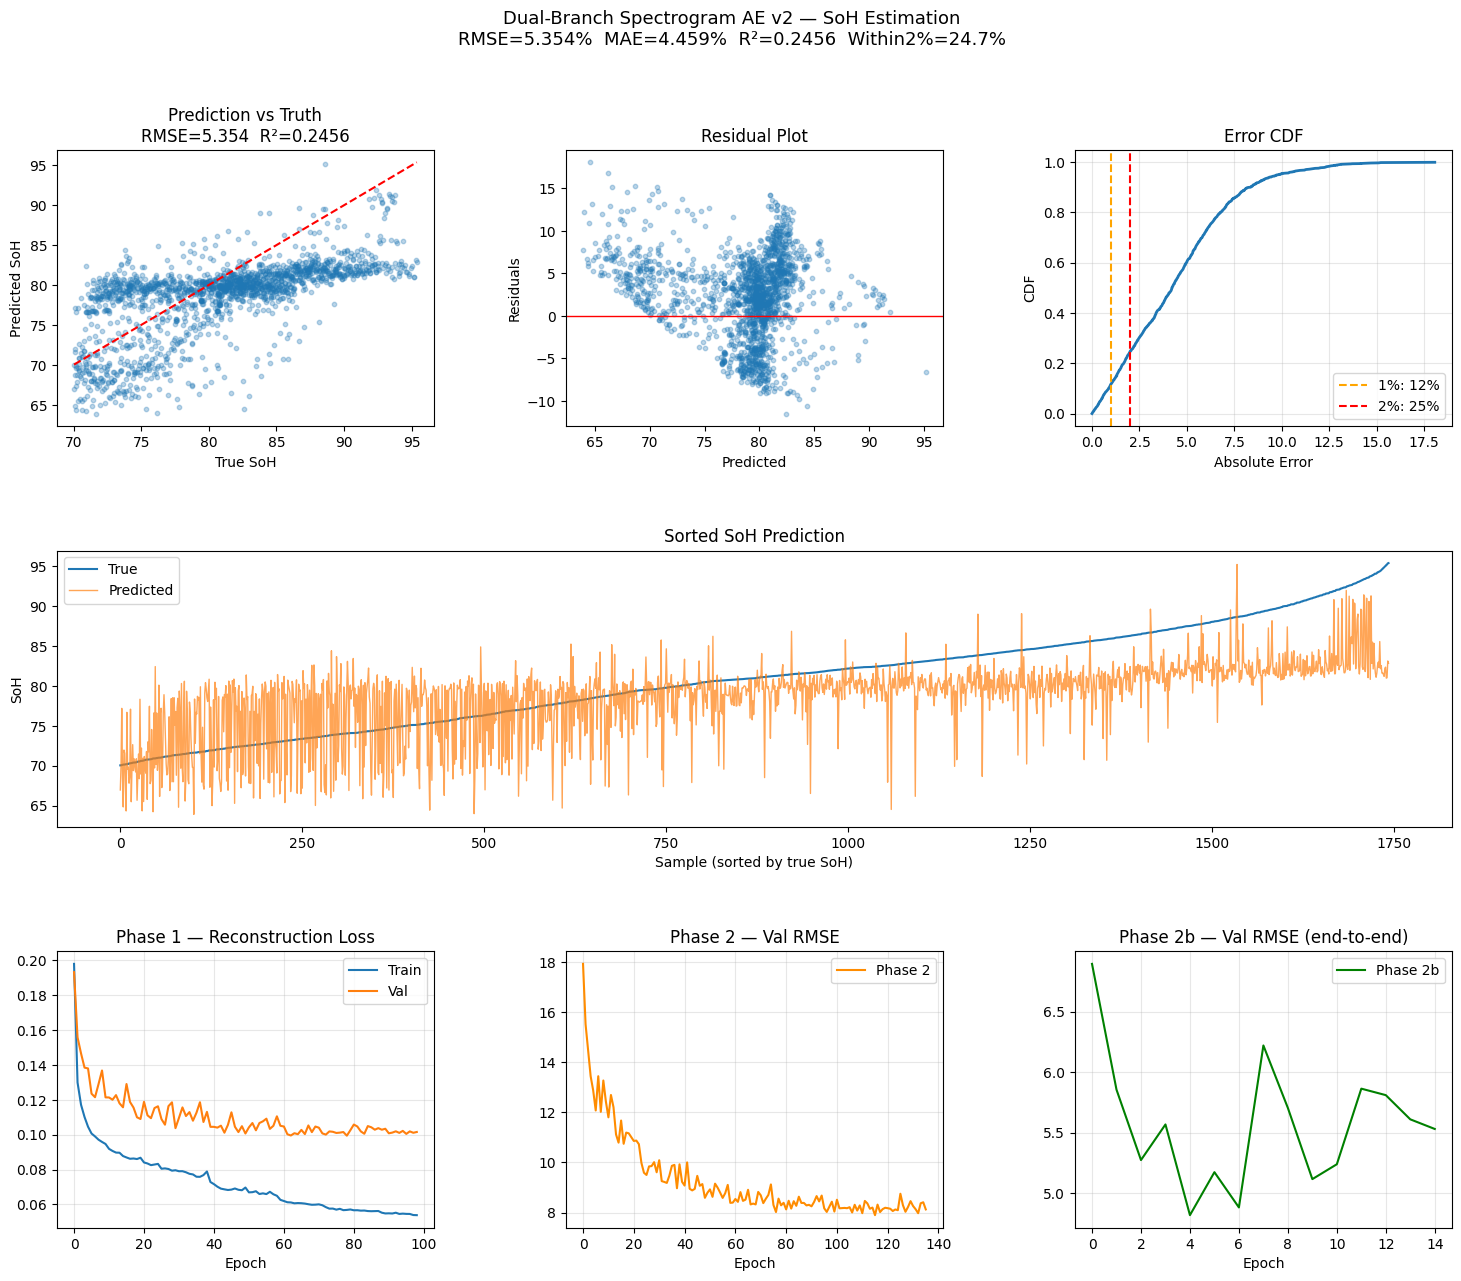

In [13]:
residuals = y_test - y_pred

fig = plt.figure(figsize=(18, 14))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

# 1: Prediction vs truth
ax = fig.add_subplot(gs[0, 0])
ax.scatter(y_test, y_pred, alpha=0.3, s=10)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ax.set_xlabel("True SoH")
ax.set_ylabel("Predicted SoH")
ax.set_title(f"Prediction vs Truth\nRMSE={rmse:.3f}  R²={r2:.4f}")

# 2: Residual plot
ax = fig.add_subplot(gs[0, 1])
ax.scatter(y_pred, residuals, alpha=0.3, s=10)
ax.axhline(0, color="r", lw=1)
ax.set_xlabel("Predicted")
ax.set_ylabel("Residuals")
ax.set_title("Residual Plot")

# 3: Error CDF
sorted_err = np.sort(errors)
cdf = np.arange(len(errors)) / len(errors)
ax = fig.add_subplot(gs[0, 2])
ax.plot(sorted_err, cdf, lw=2)
ax.axvline(1, color="orange", ls="--", label=f"1%: {within1:.0%}")
ax.axvline(2, color="red", ls="--", label=f"2%: {within2:.0%}")
ax.set_xlabel("Absolute Error")
ax.set_ylabel("CDF")
ax.set_title("Error CDF")
ax.legend()
ax.grid(alpha=0.3)

# 4: Sorted prediction
idx = np.argsort(y_test)
ax = fig.add_subplot(gs[1, :])
ax.plot(y_test[idx], label="True", lw=1.5)
ax.plot(y_pred[idx], label="Predicted", alpha=0.7, lw=1)
ax.legend()
ax.set_title("Sorted SoH Prediction")
ax.set_xlabel("Sample (sorted by true SoH)")
ax.set_ylabel("SoH")

# 5: Phase 1 training curve
ax = fig.add_subplot(gs[2, 0])
ax.plot(p1_train, label="Train")
ax.plot(p1_val, label="Val")
ax.set_title("Phase 1 — Reconstruction Loss")
ax.set_xlabel("Epoch")
ax.legend()
ax.grid(alpha=0.3)

# 6: Phase 2 val RMSE
ax = fig.add_subplot(gs[2, 1])
ax.plot(p2_val_rmse, label="Phase 2", color="darkorange")
ax.set_title("Phase 2 — Val RMSE")
ax.set_xlabel("Epoch")
ax.legend()
ax.grid(alpha=0.3)

# 7: Phase 2b val RMSE
ax = fig.add_subplot(gs[2, 2])
ax.plot(p2b_val_rmse, label="Phase 2b", color="green")
ax.set_title("Phase 2b — Val RMSE (end-to-end)")
ax.set_xlabel("Epoch")
ax.legend()
ax.grid(alpha=0.3)

fig.suptitle(
    f"Dual-Branch Spectrogram AE v2 — SoH Estimation\n"
    f"RMSE={rmse:.3f}%  MAE={mae:.3f}%  R²={r2:.4f}  "
    f"Within2%={within2:.1%}",
    fontsize=13,
)
plt.savefig(os.path.join(FIG_DIR, "Fig3_results.png"), dpi=120, bbox_inches="tight")
plt.show()

## Reconstruction Quality

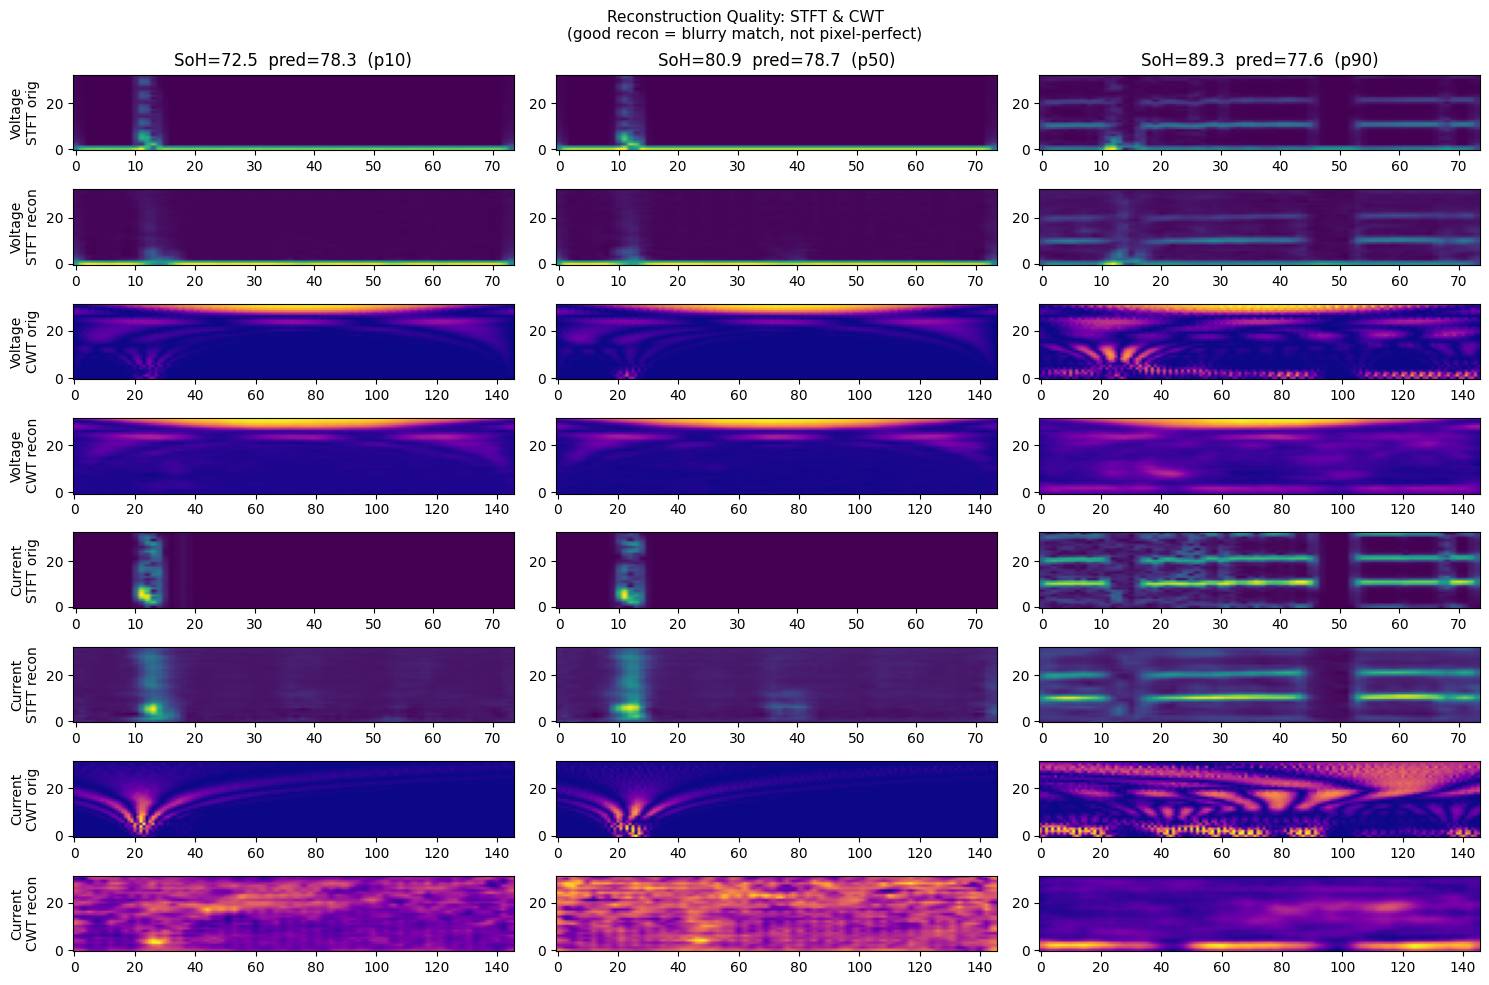

In [14]:
pcts = [10, 50, 90]
thresholds = np.percentile(y_test, pcts)
chosen = [np.argmin(np.abs(y_test - t)) for t in thresholds]
ch_show = min(2, N_CH)
ch_names = ["Voltage", "Current", "Temperature", "dV/dt", "dI/dt"]

fig, axes = plt.subplots(ch_show * 4, 3, figsize=(15, 5 * ch_show))

model.eval()
with torch.no_grad():
    for col, (idx, pct) in enumerate(zip(chosen, pcts)):
        Ss = torch.tensor(S_stft_test[idx : idx + 1], dtype=torch.float32).to(DEVICE)
        Sc = torch.tensor(S_cwt_test[idx : idx + 1], dtype=torch.float32).to(DEVICE)
        rs, rc = model(Ss, Sc, mode="reconstruct")
        rs = rs.cpu().numpy()[0]
        rc = rc.cpu().numpy()[0]

        for ch in range(ch_show):
            r0 = ch * 4
            # STFT original
            axes[r0][col].imshow(
                S_stft_test[idx, ch], aspect="auto", origin="lower", cmap="viridis"
            )
            # STFT recon
            axes[r0 + 1][col].imshow(
                rs[ch], aspect="auto", origin="lower", cmap="viridis"
            )
            # CWT original
            axes[r0 + 2][col].imshow(
                S_cwt_test[idx, ch], aspect="auto", origin="lower", cmap="plasma"
            )
            # CWT recon
            axes[r0 + 3][col].imshow(
                rc[ch], aspect="auto", origin="lower", cmap="plasma"
            )

            if col == 0:
                axes[r0][col].set_ylabel(f"{ch_names[ch]}\nSTFT orig")
                axes[r0 + 1][col].set_ylabel(f"{ch_names[ch]}\nSTFT recon")
                axes[r0 + 2][col].set_ylabel(f"{ch_names[ch]}\nCWT orig")
                axes[r0 + 3][col].set_ylabel(f"{ch_names[ch]}\nCWT recon")
            if r0 == 0:
                axes[r0][col].set_title(
                    f"SoH={y_test[idx]:.1f}  pred={y_pred[idx]:.1f}  (p{pct})"
                )

fig.suptitle(
    "Reconstruction Quality: STFT & CWT\n"
    "(good recon = blurry match, not pixel-perfect)",
    fontsize=11,
)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig4_reconstruction.png"))
plt.show()

## Save

In [15]:
joblib.dump(model, os.path.join(MODEL_DIR, "SpectroAE_v2.pkl"))
print("Model saved.")
print(f"Figures saved to: {FIG_DIR}")

Model saved.
Figures saved to: /content/figures/SpectroAE_v2
